**Estudiante:** Juan Felipe Rodríguez Galindo · 20261595004 — Taller 6 (series de tiempo), plantilla Python

# Taller Aplicado 2 — Plantilla base (trabajo autónomo)
**Benchmarking de modelos estadísticos clásicos y redes NAR/NARX sobre una serie real**

Esta plantilla trae resuelto el *andamiaje* del experimento: carga, validación del dataset, preprocesamiento sin fuga, diagnóstico, validación cruzada de origen móvil, métricas, residuos, prueba de Diebold-Mariano y exportación de resultados. **El diseño, la identificación y la optimización de los modelos son responsabilidad del equipo**: están marcados con `TODO-EQUIPO`.

El cuaderno corre de punta a punta desde el inicio con el modelo de referencia (ingenuo estacional). Los modelos que aún no implementen se omiten con un aviso.

## 0. Configuración del experimento

In [1]:
# =====================================================================
#                       CONFIGURACIÓN (editar)
# =====================================================================
DATASET     = "beijing"   # 'appliances' | 'beijing' | 'jena' | 'propio' | 'sintetico' (prueba rápida)
RUTA_PROPIA = "/content/mis_datos.csv"   # Solo si DATASET='propio'. CSV con una columna de fecha.
COL_FECHA   = "fecha"                    # Nombre de la columna de fecha en el CSV propio.

OBJETIVO    = None    # None = valor por defecto del dataset (ver diccionario FUENTES).
EXOGENAS    = None    # Lista de columnas exógenas; None = valores por defecto; [] = sin exógenas.
FRECUENCIA  = None    # Remuestreo pandas ('h', 'D', ...). None = por defecto del dataset.
S           = None    # Periodo estacional en pasos de FRECUENCIA (24 para horario-diario, 7 para diario-semanal).

PROP_PRUEBA = 0.20    # Fracción final reservada como prueba EXTERNA (no se toca hasta el final).
N_PLIEGUES  = 5       # Orígenes de la validación cruzada de origen móvil dentro de la parte de desarrollo.
HORIZONTE   = 24      # Pasos a pronosticar desde cada origen.
VENTANA     = "expandible"   # 'expandible' o 'deslizante'
LONG_VENTANA_DESLIZANTE = 2000
SEMILLA     = 2026

## 1. Librerías

In [2]:
import os, io, zipfile, urllib.request, random, time, itertools, warnings, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore")
random.seed(SEMILLA); np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})

## 2. Carga de datos
Fuentes verificadas (UCI Machine Learning Repository y TensorFlow). Las descargas se guardan en `./datos/`.

In [3]:
FUENTES = {
    "appliances": dict(url="https://archive.ics.uci.edu/static/public/374/appliances+energy+prediction.zip",
                       objetivo="Appliances", exogenas=["T_out", "RH_out", "Windspeed"], frecuencia="h", s=24),
    "beijing":    dict(url="https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip",
                       objetivo="PM2.5", exogenas=["TEMP", "DEWP", "PRES", "WSPM"], frecuencia="D", s=7,
                       estacion="Aotizhongxin"),
    "jena":       dict(url="https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip",
                       objetivo="T (degC)", exogenas=["p (mbar)", "rh (%)"], frecuencia="h", s=24),
    "propio":     dict(objetivo=None, exogenas=[], frecuencia=None, s=None),
    "sintetico":  dict(objetivo="y", exogenas=["x"], frecuencia="D", s=7),
}

def descargar(url):
    os.makedirs("datos", exist_ok=True)
    destino = os.path.join("datos", url.split("/")[-1])
    if not os.path.exists(destino):
        print("Descargando", url)
        urllib.request.urlretrieve(url, destino)
    return destino

def leer_csv_de_zip(ruta_zip, contiene=".csv"):
    # Recorre zips anidados (Beijing trae un zip dentro de otro) hasta hallar el CSV pedido.
    with zipfile.ZipFile(ruta_zip) as z:
        for nombre in z.namelist():
            if nombre.endswith(".csv") and contiene in nombre:
                return pd.read_csv(z.open(nombre))
        for nombre in z.namelist():
            if nombre.endswith(".zip"):
                return leer_csv_de_zip(io.BytesIO(z.read(nombre)), contiene)
    raise FileNotFoundError(f"No se encontró un CSV que contenga '{contiene}'")

def cargar_datos(nombre):
    f = FUENTES[nombre]
    if nombre == "appliances":
        df = leer_csv_de_zip(descargar(f["url"]), "energydata")
        df.index = pd.to_datetime(df.pop("date"))
    elif nombre == "beijing":
        df = leer_csv_de_zip(descargar(f["url"]), f["estacion"])
        df.index = pd.to_datetime(df[["year", "month", "day", "hour"]])
        df = df.drop(columns=["No", "year", "month", "day", "hour", "wd", "station"])
    elif nombre == "jena":
        df = leer_csv_de_zip(descargar(f["url"]), "jena_climate")
        df.index = pd.to_datetime(df.pop("Date Time"), format="%d.%m.%Y %H:%M:%S")
        dup = df.index.duplicated()                       # el archivo trae marcas de tiempo repetidas
        print(f"Jena: {dup.sum()} registros duplicados eliminados (documentar en el informe)")
        df = df[~dup]
    elif nombre == "propio":
        df = pd.read_csv(RUTA_PROPIA)
        df.index = pd.to_datetime(df.pop(COL_FECHA))
    else:  # serie sintética con la misma lógica del Taller 1, para probar la plantilla sin internet
        t = np.arange(1500); rng = np.random.default_rng(SEMILLA)
        x = 18 + 6*np.sin(2*np.pi*(t-80)/365.25) + rng.normal(0, 1.5, t.size)
        y = 200 + .03*t + 10*np.sin(2*np.pi*t/7) + .35*(x-18)**2 + rng.normal(0, 3, t.size)
        df = pd.DataFrame({"y": y, "x": x}, index=pd.date_range("2020-01-01", periods=t.size, freq="D"))
    return df.sort_index()

cfg = FUENTES[DATASET]
OBJ  = OBJETIVO  or cfg["objetivo"]
EXO  = cfg["exogenas"] if EXOGENAS is None else EXOGENAS
FREC = FRECUENCIA or cfg["frecuencia"]
PER  = S or cfg["s"]
crudo = cargar_datos(DATASET)
print(crudo.shape); display(crudo.head())

Descargando https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip


(35064, 11)


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
2013-03-01 00:00:00,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,4.4
2013-03-01 01:00:00,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,4.7
2013-03-01 02:00:00,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,5.6
2013-03-01 03:00:00,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,3.1
2013-03-01 04:00:00,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,2.0


## 3. Validación previa del dataset
Criterios mínimos (obligatorios para un **dataset propio** y recomendables para todos). El equipo debe reportar esta tabla en la sección de Metodología del informe.

In [4]:
def validar_dataset(df, obj, exo, frec, per):
    serie = df[obj]
    paso = pd.Series(df.index).diff().dropna()
    criterios = {
        "C1 Índice temporal monótono y sin duplicados": df.index.is_monotonic_increasing and not df.index.duplicated().any(),
        "C2 Muestreo regular (paso modal >= 90% de los casos)": (paso == paso.mode()[0]).mean() >= 0.90,
        "C3 Faltantes en objetivo <= 10%": serie.isna().mean() <= 0.10,
        "C4 Longitud >= 10 periodos estacionales tras remuestreo": len(serie.resample(frec).mean().dropna()) >= 10*per if frec else True,
        "C5 Exógenas existen y son numéricas": all(c in df and pd.api.types.is_numeric_dtype(df[c]) for c in exo),
        "C6 Objetivo no constante": serie.std() > 0,
    }
    tabla = pd.DataFrame({"Cumple": criterios}); display(tabla)
    print(f"Paso modal original: {paso.mode()[0]} | faltantes objetivo: {100*serie.isna().mean():.2f}%")
    # C7 (manual): documentar origen, licencia, unidades y significado de cada variable.
    # C8 (manual): justificar que las exógenas estarían disponibles al momento de pronosticar.
    return tabla["Cumple"].all()

assert validar_dataset(crudo, OBJ, EXO, FREC, PER), "El dataset no cumple los criterios mínimos"

,Cumple
C1 Índice temporal monótono y sin duplicados,True
C2 Muestreo regular (paso modal >= 90% de los casos),True
C3 Faltantes en objetivo <= 10%,True
C4 Longitud >= 10 periodos estacionales tras remuestreo,True
C5 Exógenas existen y son numéricas,True
C6 Objetivo no constante,True


Paso modal original: 0 days 01:00:00 | faltantes objetivo: 2.64%


## 4. Preprocesamiento sin fuga de información
Regla de oro: **todo estadístico que transforme los datos (medias, desviaciones, tendencias, imputaciones con modelos) se estima solo con la parte de entrenamiento de cada pliegue.** Aquí solo se hacen transformaciones que no usan el futuro: remuestreo por agregación e imputación por interpolación temporal local.

Faltantes imputados por columna:
 PM2.5    15
TEMP      0
DEWP      0
PRES      0
WSPM      0
dtype: int64
Total 1461 | desarrollo 1168 (2013-03-01 00:00:00 a 2016-05-11 00:00:00) | prueba externa 293 (2016-05-12 00:00:00 a 2017-02-28 00:00:00)


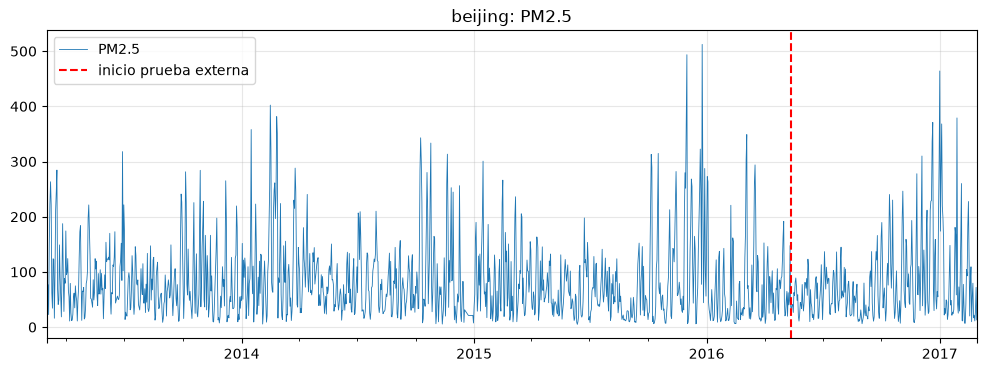

In [5]:
datos = crudo[[OBJ] + EXO].astype(float)
if FREC:
    datos = datos.resample(FREC).mean()                   # agregación causal dentro de cada intervalo
n_falt = datos.isna().sum()
datos = datos.interpolate(method="time", limit=6).ffill().bfill()   # huecos cortos; documentar en el informe
print("Faltantes imputados por columna:\n", n_falt)

N = len(datos)
n_dev = int((1 - PROP_PRUEBA) * N)                         # desarrollo = entrenamiento + validación cruzada
desarrollo, prueba = datos.iloc[:n_dev], datos.iloc[n_dev:]
print(f"Total {N} | desarrollo {len(desarrollo)} ({desarrollo.index[0]} a {desarrollo.index[-1]}) | "
      f"prueba externa {len(prueba)} ({prueba.index[0]} a {prueba.index[-1]})")

ax = datos[OBJ].plot(lw=.6, title=f"{DATASET}: {OBJ}")
ax.axvline(prueba.index[0], c="r", ls="--", label="inicio prueba externa"); ax.legend(); plt.show()

## 5. Diagnóstico estadístico (solo desarrollo)

nivel                ADF p=0.0000 | KPSS p=0.1000
(1-B^7)              ADF p=0.0000 | KPSS p=0.1000
(1-B)(1-B^7)         ADF p=0.0000 | KPSS p=0.1000


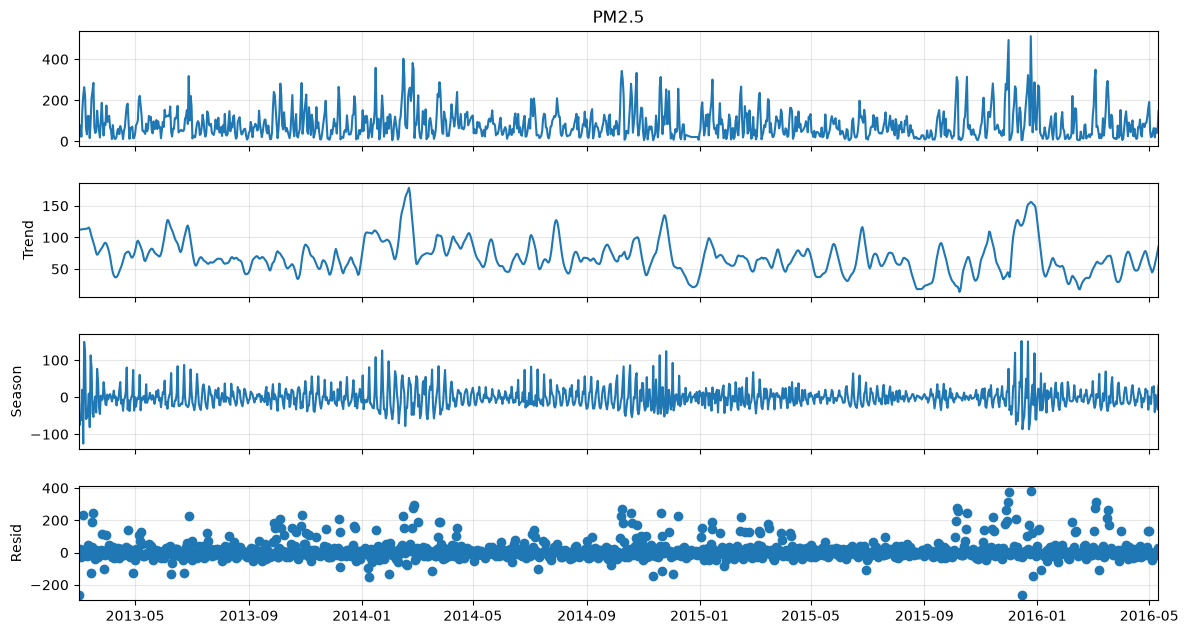

F_T=0.200  F_S=0.071


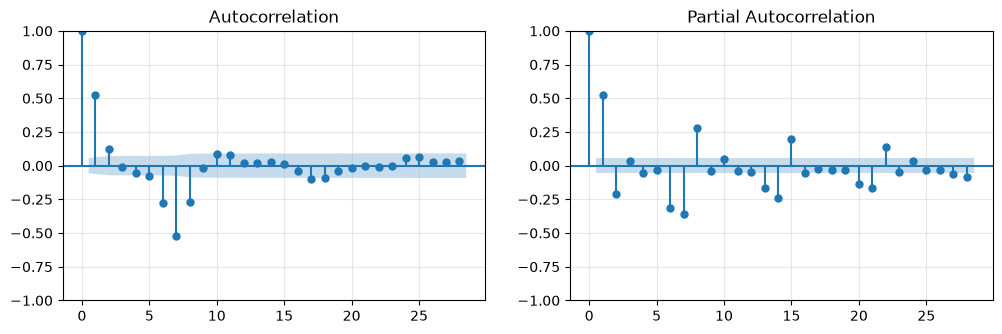

,PM2.5,TEMP,DEWP,PRES,WSPM
PM2.5,1.000,-0.087,0.142,-0.017,-0.380
TEMP,-0.087,1.000,0.899,-0.862,-0.197
DEWP,0.142,0.899,1.000,-0.789,-0.450
PRES,-0.017,-0.862,-0.789,1.000,0.176
WSPM,-0.380,-0.197,-0.450,0.176,1.000


In [6]:
y_dev = desarrollo[OBJ]
for nombre, z in [("nivel", y_dev), (f"(1-B^{PER})", y_dev.diff(PER).dropna()),
                  (f"(1-B)(1-B^{PER})", y_dev.diff().diff(PER).dropna())]:
    print(f"{nombre:<20s} ADF p={adfuller(z, autolag='AIC')[1]:.4f} | KPSS p={kpss(z, nlags='auto')[1]:.4f}")

stl = STL(y_dev, period=PER, robust=True).fit()
stl.plot(); plt.gcf().set_size_inches(12, 7); plt.show()
F_T = max(0, 1 - np.var(stl.resid)/np.var(stl.trend + stl.resid))
F_S = max(0, 1 - np.var(stl.resid)/np.var(stl.seasonal + stl.resid))
print(f"F_T={F_T:.3f}  F_S={F_S:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(y_dev.diff(PER).dropna(), lags=4*PER, ax=ax[0]); plot_pacf(y_dev.diff(PER).dropna(), lags=4*PER, ax=ax[1], method="ywm")
plt.show()
if EXO:
    display(desarrollo.corr().round(3))

Asimetría de y: 1.77 | de log(1+y): -0.28


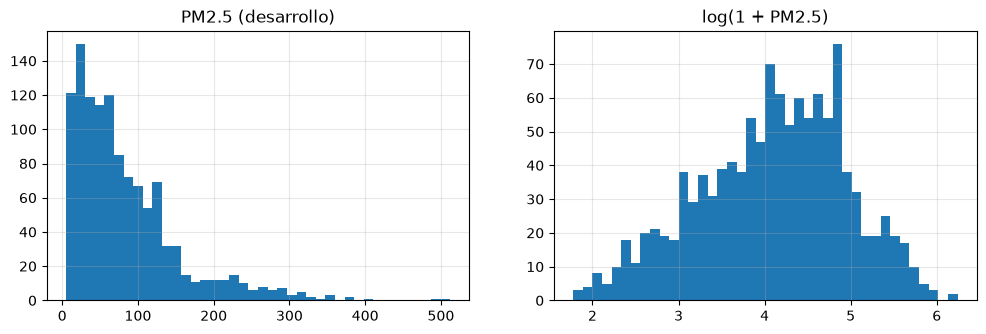

In [7]:
# Transformación log(1 + PM2.5): la serie es positiva, muy asimétrica y su varianza crece con el nivel.
# Es punto a punto (no usa estadísticos de otros instantes), así que no introduce fuga.
print(f"Asimetría de y: {stats.skew(y_dev):.2f} | de log(1+y): {stats.skew(np.log1p(y_dev)):.2f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(y_dev, bins=40); ax[0].set_title(f"{OBJ} (desarrollo)")
ax[1].hist(np.log1p(y_dev), bins=40); ax[1].set_title(f"log(1 + {OBJ})")
plt.show()

## 6. Validación cruzada de origen móvil
Para el pliegue $k$ con origen $o_k$: se entrena con $\{1,\dots,o_k-1\}$ (o una ventana deslizante) y se evalúa en $\{o_k,\dots,o_k+H-1\}$. Los orígenes se reparten en el último 40% del bloque de desarrollo. Así se respeta el orden temporal (Bergmeir & Benítez, 2012; Hyndman & Athanasopoulos, 2021, §5.10).

In [8]:
def pliegues_origen_movil(n, n_pliegues, H, ventana="expandible", long_vent=2000, inicio=0.6):
    o_min, o_max = int(inicio*n), n - H
    origenes = np.linspace(o_min, o_max, n_pliegues).astype(int)
    for o in origenes:
        ini = 0 if ventana == "expandible" else max(0, o - long_vent)
        yield np.arange(ini, o), np.arange(o, o + H)

for k, (itr, ite) in enumerate(pliegues_origen_movil(len(desarrollo), N_PLIEGUES, HORIZONTE, VENTANA, LONG_VENTANA_DESLIZANTE)):
    print(f"Pliegue {k+1}: entrena {desarrollo.index[itr[0]]} a {desarrollo.index[itr[-1]]} "
          f"-> evalúa {desarrollo.index[ite[0]]} a {desarrollo.index[ite[-1]]}")

Pliegue 1: entrena 2013-03-01 00:00:00 a 2015-01-29 00:00:00 -> evalúa 2015-01-30 00:00:00 a 2015-02-22 00:00:00
Pliegue 2: entrena 2013-03-01 00:00:00 a 2015-05-20 00:00:00 -> evalúa 2015-05-21 00:00:00 a 2015-06-13 00:00:00
Pliegue 3: entrena 2013-03-01 00:00:00 a 2015-09-08 00:00:00 -> evalúa 2015-09-09 00:00:00 a 2015-10-02 00:00:00
Pliegue 4: entrena 2013-03-01 00:00:00 a 2015-12-28 00:00:00 -> evalúa 2015-12-29 00:00:00 a 2016-01-21 00:00:00
Pliegue 5: entrena 2013-03-01 00:00:00 a 2016-04-17 00:00:00 -> evalúa 2016-04-18 00:00:00 a 2016-05-11 00:00:00


## 7. Modelos
**Contrato de todos los modelos:** `pronosticar(y_hist, X_hist, X_fut, H, **hp) -> np.ndarray de largo H`.
- `y_hist`: Serie (pandas) de entrenamiento del pliegue. `X_hist`: DataFrame de exógenas alineado (puede estar vacío).
- `X_fut`: exógenas del horizonte (supuesto de exógena conocida; si el equipo pronostica la exógena, debe hacerlo dentro de esta función).
- `hp`: hiperparámetros, para el análisis de sensibilidad.
- Dentro de la función se ajusta TODO lo dependiente de datos (escaladores, tendencias): así no hay fuga.

### 7.1 Identificación del modelo clásico (AIC/BIC)

In [9]:
# Identificación del modelo clásico: AIC y BIC sobre el bloque de desarrollo (nunca sobre la prueba).
from statsmodels.tsa.statespace.sarimax import SARIMAX
z_dev = np.log1p(y_dev)
filas = []
for p, q, (P, Q) in itertools.product([0, 1, 2], [0, 1, 2], [(0, 0), (1, 1)]):
    r = SARIMAX(z_dev, exog=desarrollo[EXO], order=(p, 0, q), seasonal_order=(P, 0, Q, PER), trend="c").fit(disp=False)
    filas.append({"orden": (p, 0, q), "estacional": (P, 0, Q, PER), "AIC": r.aic, "BIC": r.bic})
display(pd.DataFrame(filas).sort_values("AIC").head(6).round(1))

elegido = SARIMAX(z_dev, exog=desarrollo[EXO], order=(1, 0, 1), seasonal_order=(0, 0, 0, PER), trend="c").fit(disp=False)
print(elegido.summary().tables[1])
print("Ljung-Box de los residuos del modelo elegido:\n", acorr_ljungbox(elegido.resid, lags=[PER, 2*PER, 3*PER]).round(4))

,orden,estacional,AIC,BIC
8,"(1, 0, 1)","(0, 0, 0, 7)",1991.2,2031.7
10,"(1, 0, 2)","(0, 0, 0, 7)",2003.7,2049.3
11,"(1, 0, 2)","(1, 0, 1, 7)",2006.4,2062.1
14,"(2, 0, 1)","(0, 0, 0, 7)",2016.5,2062.1
15,"(2, 0, 1)","(1, 0, 1, 7)",2019.9,2075.6
6,"(1, 0, 0)","(0, 0, 0, 7)",2022.9,2058.4


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.3548      0.638      0.556      0.578      -0.896       1.605
TEMP          -0.0612      0.007     -8.174      0.000      -0.076      -0.047
DEWP           0.1100      0.005     21.681      0.000       0.100       0.120
PRES           0.0024      0.004      0.556      0.578      -0.006       0.011
WSPM          -0.1231      0.026     -4.767      0.000      -0.174      -0.072
ar.L1          0.8538      0.021     40.141      0.000       0.812       0.896
ma.L1         -0.3522      0.040     -8.754      0.000      -0.431      -0.273
sigma2         0.3178      0.013     24.393      0.000       0.292       0.343
Ljung-Box de los residuos del modelo elegido:
      lb_stat  lb_pvalue
7    70.9398        0.0
14  176.2333        0.0
21  233.0882        0.0


### 7.2 Modelos

In [10]:
import tensorflow as tf
def ingenuo_estacional(y_hist, X_hist, X_fut, H, **hp):
    # Referencia obligatoria: repite el último ciclo estacional observado.
    ult = y_hist.values[-PER:]
    return np.array([ult[h % PER] for h in range(H)])

def modelo_clasico(y_hist, X_hist, X_fut, H, **hp):
    # ARIMAX(p,0,q) con exógenas sobre log(1+y); (P,Q) estacionales en cero según AIC/BIC y F_S.
    z = np.log1p(y_hist)
    exo = X_hist if len(X_hist.columns) else None
    m = SARIMAX(z, exog=exo, order=(hp["p"], 0, hp["q"]),
                seasonal_order=(hp["P"], 0, hp["Q"], PER), trend="c").fit(disp=False)
    f = m.forecast(H, exog=X_fut if len(X_fut.columns) else None)
    return np.expm1(f.values)

def retardos(ys, xs, k, dy, dx):
    # Regresores del instante k: [y_{k-1}, ..., y_{k-dy} | x_k, ..., x_{k-dx}]
    z = ys[k-dy:k][::-1]
    if xs is not None:
        z = np.r_[z, xs[k-dx:k+1][::-1].ravel()]
    return z

def modelo_neuronal(y_hist, X_hist, X_fut, H, **hp):
    dy, dx = hp["dy"], hp["dx"]
    # 1) Escalado con estadísticos SOLO de y_hist y X_hist (sin fuga)
    yl = np.log1p(y_hist.values)
    mu, sd = yl.mean(), yl.std()
    ys = np.r_[(yl - mu) / sd, np.zeros(H)]          # los H huecos se llenan en lazo cerrado
    xs = None
    if hp["exogenas"] and len(X_hist.columns):
        mx, sx = X_hist.values.mean(axis=0), X_hist.values.std(axis=0)
        xs = (np.vstack([X_hist.values, X_fut.values]) - mx) / sx
    # 2) Regresores con retardos (lazo abierto: los retardos son valores reales)
    n = len(y_hist)
    idx = np.arange(max(dy, dx), n)
    Z = np.array([retardos(ys, xs, k, dy, dx) for k in idx])
    T = ys[idx]
    # 3) La cola (15 %) de y_hist es la validación para la parada temprana
    nv = int(0.15 * len(idx))
    tf.keras.utils.set_random_seed(hp["semilla"])
    red = tf.keras.Sequential([
        tf.keras.Input(shape=(Z.shape[1],)),
        tf.keras.layers.Dense(hp["neuronas"], activation="tanh",
                              kernel_regularizer=tf.keras.regularizers.l2(1e-4)),
        tf.keras.layers.Dense(1)])
    red.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    red.fit(Z[:-nv], T[:-nv], validation_data=(Z[-nv:], T[-nv:]), epochs=300, batch_size=32, verbose=0,
            callbacks=[tf.keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)])
    # 4) Lazo cerrado: cada predicción entra como retardo de la siguiente
    for k in range(n, n + H):
        ys[k] = red(retardos(ys, xs, k, dy, dx)[None, :], training=False).numpy()[0, 0]
    # 5) Desescalar y deshacer el logaritmo
    return np.expm1(ys[n:] * sd + mu)

HP_CLASICO = {"p": 1, "q": 1, "P": 0, "Q": 0}
HP_RED     = {"dy": 14, "dx": 2, "neuronas": 10, "semilla": SEMILLA}
MODELOS = {"Ingenuo estacional": (ingenuo_estacional, {}),
           "Clásico":            (modelo_clasico, HP_CLASICO),
           "Neuronal":           (modelo_neuronal, {**HP_RED, "exogenas": True}),
           "NAR":                (modelo_neuronal, {**HP_RED, "exogenas": False})}


## 8. Motor de evaluación (no modificar)

In [11]:
ESC_MASE = np.mean(np.abs(y_dev.values[PER:] - y_dev.values[:-PER]))   # escala MASE con desarrollo

def metricas(yr, yp):
    yr, yp = np.asarray(yr, float), np.asarray(yp, float); e = yr - yp
    nz = np.abs(yr) > 1e-8
    return {"RMSE": np.sqrt(np.mean(e**2)), "MAE": np.mean(np.abs(e)),
            "MAPE(%)": 100*np.mean(np.abs(e[nz]/yr[nz])) if nz.any() else np.nan,
            "sMAPE(%)": 200*np.mean(np.abs(e)/(np.abs(yr)+np.abs(yp)+1e-12)), "MASE": np.mean(np.abs(e))/ESC_MASE}

def evaluar(fun, hp, base, pliegues):
    reales, preds, tiempo = [], [], 0.0
    for itr, ite in pliegues:
        yh, Xh = base[OBJ].iloc[itr], base[EXO].iloc[itr]
        Xf = base[EXO].iloc[ite]
        t0 = time.time()
        p = np.asarray(fun(yh, Xh, Xf, len(ite), **hp), float).ravel()
        tiempo += time.time() - t0
        assert p.shape == (len(ite),), "El modelo debe devolver H valores"
        reales.append(base[OBJ].iloc[ite].values); preds.append(p)
    return np.array(reales), np.array(preds), tiempo

def correr_benchmark(base, pliegues, modelos):
    res, salidas = {}, {}
    for nombre, (fun, hp) in modelos.items():
        try:
            R, P, tt = evaluar(fun, hp, base, list(pliegues))
        except NotImplementedError:
            print(f"[aviso] '{nombre}' aún no implementado: se omite."); continue
        res[nombre] = {**metricas(R.ravel(), P.ravel()), "Tiempo(s)": tt}
        salidas[nombre] = (R, P)
    return pd.DataFrame(res).T, salidas

pl_cv = list(pliegues_origen_movil(len(desarrollo), N_PLIEGUES, HORIZONTE, VENTANA, LONG_VENTANA_DESLIZANTE))
tabla_cv, salidas_cv = correr_benchmark(desarrollo, pl_cv, MODELOS)
print(f"Validación cruzada de origen móvil ({N_PLIEGUES} pliegues, H={HORIZONTE})"); display(tabla_cv.round(4))

Validación cruzada de origen móvil (5 pliegues, H=24)


,RMSE,MAE,MAPE(%),sMAPE(%),MASE,Tiempo(s)
Ingenuo estacional,110.5323,71.6894,194.2491,85.0649,1.0046,0.0000
Clásico,52.5022,37.1692,86.0689,57.6717,0.5208,1.8415
Neuronal,43.3311,30.0607,62.2225,48.9266,0.4212,29.7860
NAR,59.7522,43.3551,119.2477,65.2447,0.6075,25.8889


## 9. Análisis de sensibilidad de hiperparámetros
Defina una rejilla por modelo (mínimo 2 hiperparámetros × 3 niveles para el modelo neuronal). Se reporta media y desviación del RMSE por pliegue, y se recomienda repetir con ≥ 3 semillas para redes.

,p,q,RMSE medio,RMSE desv,Tiempo(s)
1,1,1,50.6641,13.7705,1.7022
2,1,2,51.3282,11.8846,2.0597
3,2,0,52.1482,11.8361,2.1864
8,3,2,52.2704,10.2473,1.0492
5,2,2,52.2707,10.2475,0.9440
4,2,1,53.5692,12.7503,1.4052
0,1,0,54.1532,13.6006,0.9959
6,3,0,59.8770,13.7565,2.3582
7,3,1,74.2336,40.1342,2.7132


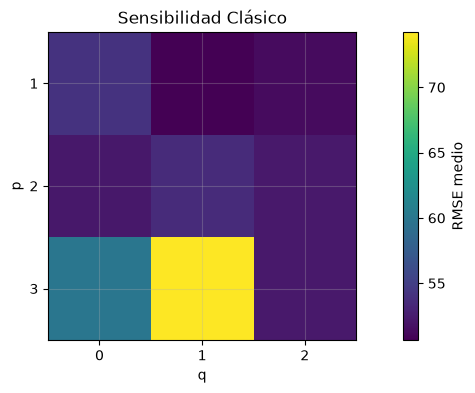

,dy,neuronas,semilla,RMSE medio,RMSE desv,Tiempo(s)
8,7,20,3,38.5803,11.1404,17.1181
5,7,10,3,38.7397,10.3866,21.8776
6,7,20,1,38.8552,10.8212,17.1765
7,7,20,2,38.9718,9.6719,20.9349
12,14,10,1,39.0024,11.0923,19.0629
0,7,5,1,39.3608,9.1697,22.3439
1,7,5,2,41.2873,13.8280,33.4828
17,14,20,3,41.3242,8.0282,16.3350
3,7,10,1,41.5716,9.8725,20.9510
20,28,5,3,41.6904,12.1330,24.1726


In [12]:
REJILLAS = {
    "Clásico":  {"p": [1, 2, 3], "q": [0, 1, 2]},
    "Neuronal": {"dy": [7, 14, 28], "neuronas": [5, 10, 20], "semilla": [1, 2, 3]},
}

def sensibilidad(nombre, rejilla):
    fun, hp_base = MODELOS[nombre]
    claves = list(rejilla)
    filas = []
    for valores in itertools.product(*[rejilla[k] for k in claves]):
        hp = {**hp_base, **dict(zip(claves, valores))}
        R, P, tt = evaluar(fun, hp, desarrollo, pl_cv)
        rmse_pl = np.sqrt(np.mean((R - P)**2, axis=1))
        filas.append({**dict(zip(claves, valores)), "RMSE medio": rmse_pl.mean(), "RMSE desv": rmse_pl.std(), "Tiempo(s)": tt})
    t = pd.DataFrame(filas).sort_values("RMSE medio"); display(t.round(4))
    if len(claves) == 2:   # mapa de calor para dos hiperparámetros
        piv = t.pivot(index=claves[0], columns=claves[1], values="RMSE medio")
        plt.imshow(piv, cmap="viridis"); plt.colorbar(label="RMSE medio")
        plt.xticks(range(piv.shape[1]), piv.columns); plt.yticks(range(piv.shape[0]), piv.index)
        plt.xlabel(claves[1]); plt.ylabel(claves[0]); plt.title(f"Sensibilidad {nombre}"); plt.show()
    return t

tablas_sens = {m: sensibilidad(m, g) for m, g in REJILLAS.items()}

,dy,neuronas,mean,std
2,7,20,38.802,0.201
1,7,10,41.330,2.479
4,14,10,41.698,2.616
0,7,5,41.873,2.851
5,14,20,42.140,0.981
3,14,5,42.792,0.784
8,28,20,45.240,2.836
6,28,5,46.039,7.041
7,28,10,50.135,1.838


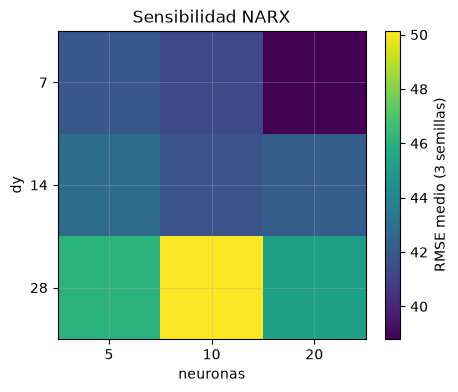

Elegidos: {'p': 1, 'q': 1, 'P': 0, 'Q': 0} {'dy': 7, 'dx': 2, 'neuronas': 20, 'semilla': 2026}


Validación cruzada con los hiperparámetros elegidos


,RMSE,MAE,MAPE(%),sMAPE(%),MASE,Tiempo(s)
Ingenuo estacional,110.5323,71.6894,194.2491,85.0649,1.0046,0.0000
Clásico,52.5022,37.1692,86.0689,57.6717,0.5208,1.8659
Neuronal,42.8117,31.8544,63.1340,51.1565,0.4464,21.6779
NAR,61.3766,44.4080,124.0094,66.9615,0.6223,25.5172


In [13]:
# La rejilla de la red tiene 3 claves (dy, neuronas, semilla): promedio sobre las semillas.
t = tablas_sens["Neuronal"]
red_sem = t.groupby(["dy", "neuronas"])["RMSE medio"].agg(["mean", "std"]).reset_index()
display(red_sem.sort_values("mean").round(3))
piv = red_sem.pivot(index="dy", columns="neuronas", values="mean")
plt.figure(figsize=(5, 4))
plt.imshow(piv, cmap="viridis"); plt.colorbar(label="RMSE medio (3 semillas)")
plt.xticks(range(piv.shape[1]), piv.columns); plt.yticks(range(piv.shape[0]), piv.index)
plt.xlabel("neuronas"); plt.ylabel("dy"); plt.title("Sensibilidad NARX"); plt.show()

# Hiperparámetros elegidos SOLO con la validación cruzada (la prueba externa sigue sin tocarse)
mejor_c = tablas_sens["Clásico"].iloc[0]
mejor_r = red_sem.loc[red_sem["mean"].idxmin()]
HP_CLASICO.update(p=int(mejor_c["p"]), q=int(mejor_c["q"]))
HP_RED.update(dy=int(mejor_r["dy"]), neuronas=int(mejor_r["neuronas"]))
MODELOS["Clásico"]  = (modelo_clasico, HP_CLASICO)
MODELOS["Neuronal"] = (modelo_neuronal, {**HP_RED, "exogenas": True})
MODELOS["NAR"]      = (modelo_neuronal, {**HP_RED, "exogenas": False})
print("Elegidos:", HP_CLASICO, HP_RED)

tabla_cv, salidas_cv = correr_benchmark(desarrollo, pl_cv, MODELOS)
print("Validación cruzada con los hiperparámetros elegidos"); display(tabla_cv.round(4))

## 10. Evaluación final en la prueba externa (una sola vez, con los hiperparámetros elegidos)

Prueba externa: 12 orígenes, H=24


,RMSE,MAE,MAPE(%),sMAPE(%),MASE,Tiempo(s)
Ingenuo estacional,96.2395,69.4932,175.6126,86.3006,0.9738,0.0001
Clásico,68.4711,43.5502,80.1265,56.7341,0.6103,6.3093
Neuronal,49.6144,29.3332,49.3029,40.4724,0.4110,62.4083
NAR,76.0368,48.3028,97.8692,64.1294,0.6768,39.7266


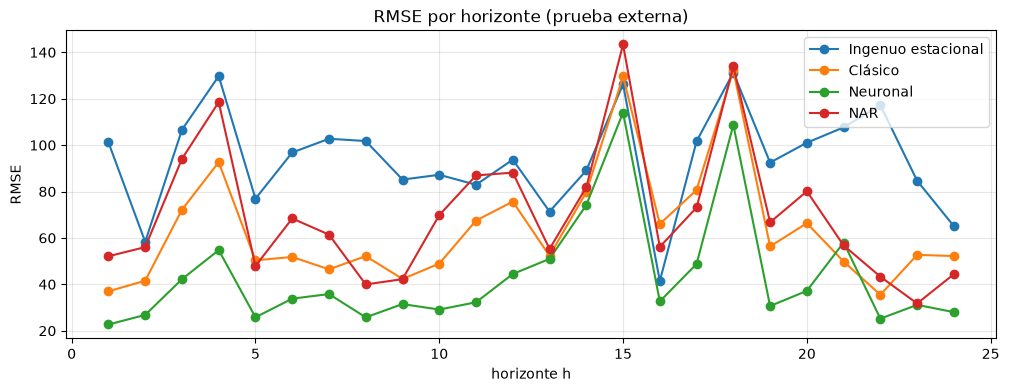

In [14]:
pl_test = list(pliegues_origen_movil(N, max(1, (len(prueba) - HORIZONTE)//HORIZONTE + 1), HORIZONTE,
                                     VENTANA, LONG_VENTANA_DESLIZANTE, inicio=n_dev/N))
tabla_test, salidas_test = correr_benchmark(datos, pl_test, MODELOS)
print(f"Prueba externa: {len(pl_test)} orígenes, H={HORIZONTE}"); display(tabla_test.round(4))

plt.figure()
for m, (R, P) in salidas_test.items():
    plt.plot(range(1, HORIZONTE+1), np.sqrt(np.mean((R-P)**2, axis=0)), marker="o", label=m)
plt.xlabel("horizonte h"); plt.ylabel("RMSE"); plt.title("RMSE por horizonte (prueba externa)"); plt.legend(); plt.show()

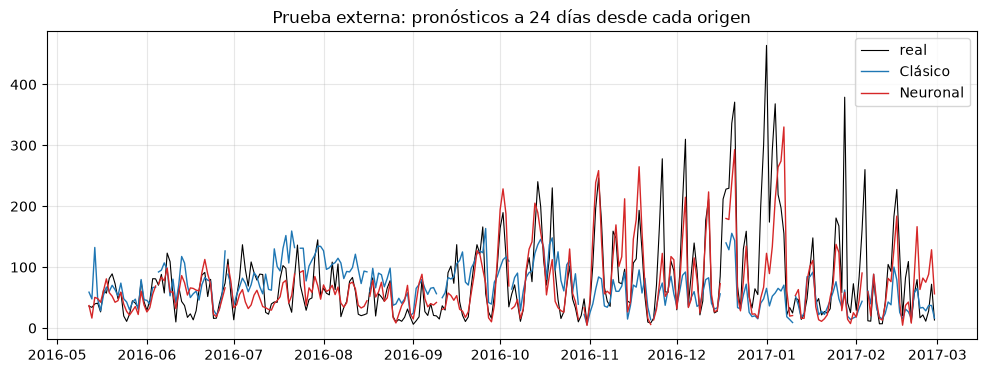

In [15]:
# Pronósticos de la prueba externa: los 12 orígenes, cada uno con sus 24 días pronosticados
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(prueba.index, prueba[OBJ], color="k", lw=.8, label="real")
for m, c in [("Clásico", "tab:blue"), ("Neuronal", "tab:red")]:
    R, P = salidas_test[m]
    for j, (_, ite) in enumerate(pl_test):
        ax.plot(datos.index[ite], P[j], color=c, lw=1, label=m if j == 0 else None)
ax.set_title("Prueba externa: pronósticos a 24 días desde cada origen"); ax.legend(); plt.show()

## 11. Residuos y significancia estadística

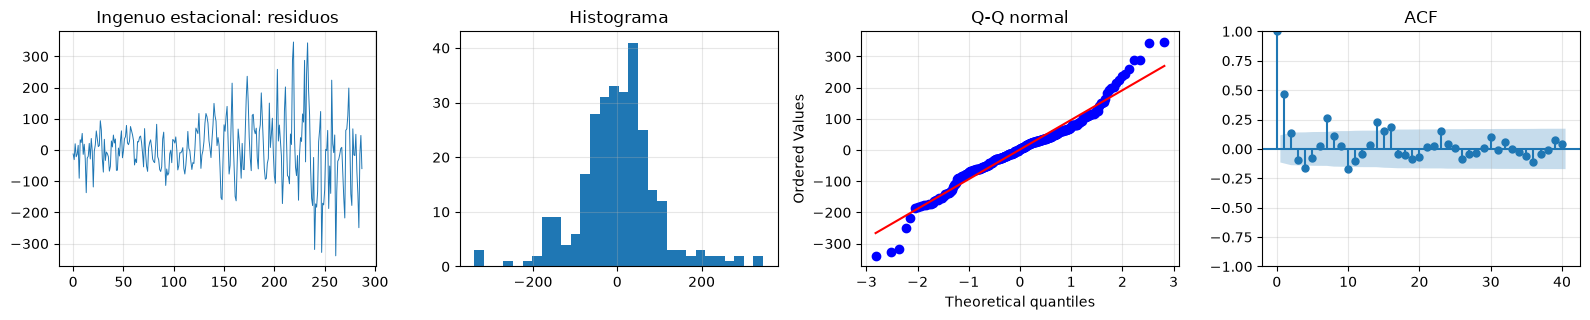

   lb_stat  lb_pvalue
7  102.272        0.0


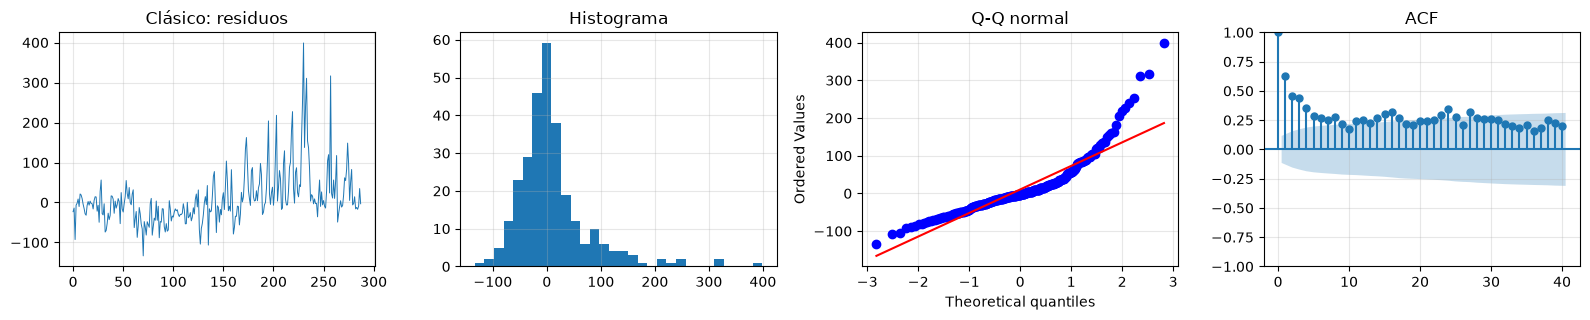

    lb_stat  lb_pvalue
7  335.7766        0.0


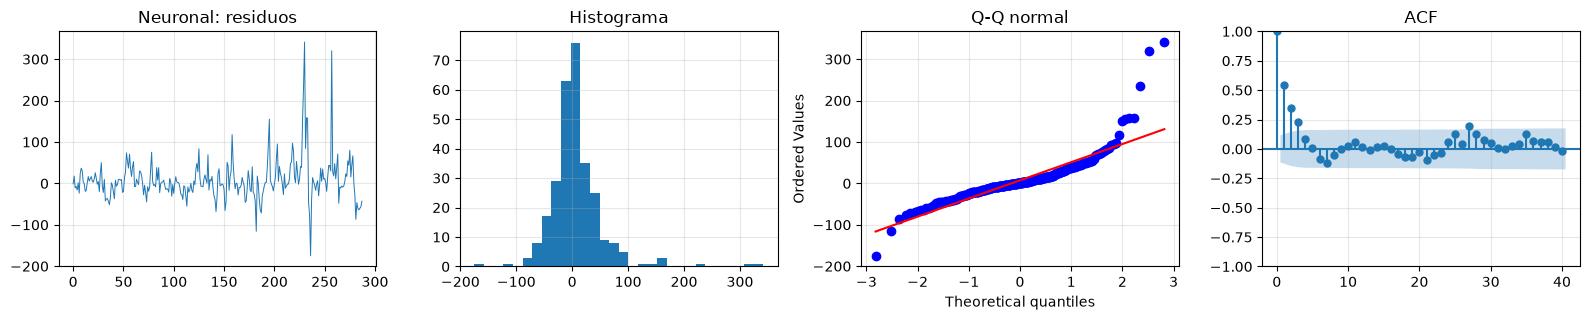

    lb_stat  lb_pvalue
7  144.1828        0.0


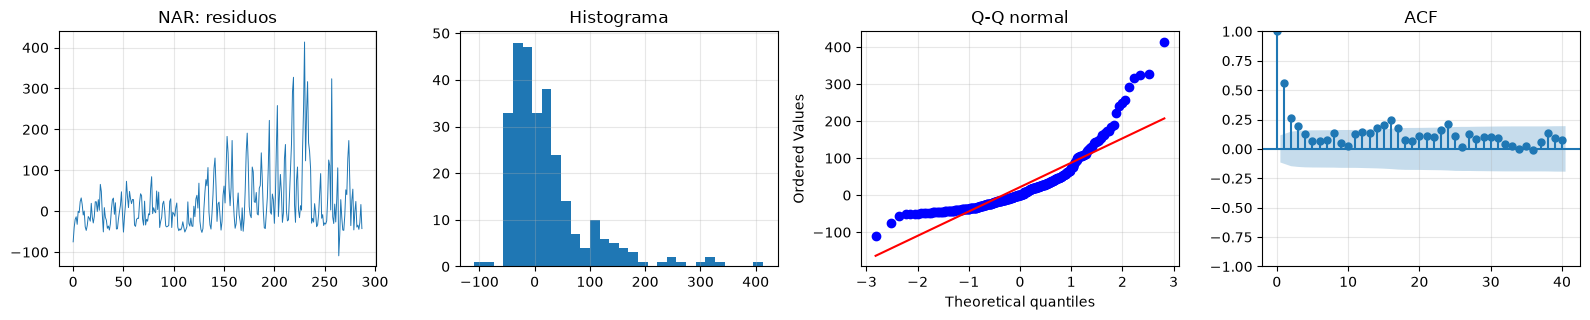

    lb_stat  lb_pvalue
7  131.6919        0.0
DM Ingenuo estacional vs Clásico: DM*=2.608, p=0.0096
DM Ingenuo estacional vs Neuronal: DM*=2.807, p=0.0053
DM Ingenuo estacional vs NAR: DM*=2.340, p=0.0200
DM Clásico vs Neuronal: DM*=2.246, p=0.0255
DM Clásico vs NAR: DM*=-1.357, p=0.1760
DM Neuronal vs NAR: DM*=-1.943, p=0.0530


In [16]:
def graficar_residuos(nombre, R, P):
    e_all = (R - P).ravel()
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.3))
    ax[0].plot(e_all, lw=.7); ax[0].set_title(f"{nombre}: residuos")
    ax[1].hist(e_all, bins=30); ax[1].set_title("Histograma")
    stats.probplot(e_all, dist="norm", plot=ax[2]); ax[2].set_title("Q-Q normal")
    plot_acf(e_all, lags=min(40, len(e_all)//3), ax=ax[3]); ax[3].set_title("ACF")
    plt.tight_layout(); plt.show()
    print(acorr_ljungbox(e_all, lags=[min(PER, len(e_all)//4)]).round(4))

def diebold_mariano(e1, e2, h=1):
    d = e1**2 - e2**2; T = len(d)
    g = [np.sum((d[k:]-d.mean())*(d[:T-k]-d.mean()))/T for k in range(h)]
    dm = d.mean()/np.sqrt((g[0] + 2*sum(g[1:]))/T) * np.sqrt((T+1-2*h+h*(h-1)/T)/T)
    return dm, 2*stats.t.sf(abs(dm), T-1)

for m, (R, P) in salidas_test.items():
    graficar_residuos(m, R, P)
nombres = list(salidas_test)
for a, b in itertools.combinations(nombres, 2):
    Ra, Pa = salidas_test[a]; Rb, Pb = salidas_test[b]
    dm, p = diebold_mariano((Ra-Pa).ravel(), (Rb-Pb).ravel(), h=HORIZONTE)
    print(f"DM {a} vs {b}: DM*={dm:.3f}, p={p:.4f}")

## 12. Exportación para el informe

In [17]:
os.makedirs("resultados", exist_ok=True)
tabla_cv.to_csv("resultados/benchmark_cv.csv"); tabla_test.to_csv("resultados/benchmark_prueba.csv")
for m, t in tablas_sens.items():
    t.to_csv(f"resultados/sensibilidad_{m}.csv", index=False)
json.dump({"dataset": DATASET, "objetivo": OBJ, "exogenas": EXO, "frecuencia": FREC, "S": PER,
           "horizonte": HORIZONTE, "pliegues": N_PLIEGUES, "ventana": VENTANA,
           "hiperparametros": {m: hp for m, (_, hp) in MODELOS.items()}},
          open("resultados/configuracion.json", "w"), indent=2, default=str)
print("Archivos en ./resultados:", os.listdir("resultados"))

Archivos en ./resultados: ['benchmark_cv.csv', 'sensibilidad_Clásico.csv', 'benchmark_prueba.csv', 'sensibilidad_Neuronal.csv', 'configuracion.json']


## 13. Conclusiones
1. PM2.5 diario es estacionaria en nivel (ADF p < 0,001; KPSS p ≥ 0,10), con estacionalidad semanal débil (F_S = 0,071); el logaritmo baja la asimetría de 1,77 a −0,28.
2. AIC, BIC y la rejilla de validación eligen el mismo clásico: ARIMAX(1,0,1) con clima. El punto de rocío sube la contaminación (+0,110) y el viento la baja (−0,123).
3. En la red pesan más los retardos que las neuronas: d_y = 7 con 20 neuronas da el menor RMSE medio entre semillas (38,80, desviación 0,20); con d_y = 28 sube a 45–50.
4. En la prueba externa la NARX gana: MASE 0,411 frente a 0,610 del clásico, con Diebold-Mariano p = 0,026. Sin clima, la NAR (0,677) no supera al clásico, y NARX frente a NAR da p = 0,053.
5. La ventaja de la NARX depende de conocer el clima futuro, y la red tarda casi 10 veces más que el clásico (62 s frente a 6 s en la prueba).